#Standardization

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('Social_Network_Ads.csv')

In [3]:
df.sample(5)

,Age,EstimatedSalary,Purchased
192,29,43000,0
327,42,75000,0
70,25,80000,0
278,52,38000,1
32,21,16000,0


#train test split

In [4]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df.drop('Purchased',axis=1),
                                                df['Purchased'],
                                                test_size=0.3,
                                                random_state=2)

X_train.shape,X_test.shape

((280, 2), (120, 2))

In [5]:
X_train.head(2)

,Age,EstimatedSalary
112,38,61000
209,46,22000


#Standar Scalar

In [46]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [22]:
scaler.mean_

array([3.77642857e+01, 6.99000000e+04])

In [23]:
X_train_scaled.head(2)

,Age,EstimatedSalary
0,0.022734,-0.263890
1,0.794317,-1.420262


In [13]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [14]:
np.round(X_train.describe(),1)

,Age,EstimatedSalary
count,280.0,280.0
mean,37.8,69900.0
std,10.4,33786.6
min,18.0,15000.0
25%,30.0,43750.0
50%,37.0,70500.0
75%,46.0,87000.0
max,60.0,150000.0


In [15]:
np.round(X_train_scaled.describe(),1)

,Age,EstimatedSalary
count,280.0,280.0
mean,0.0,0.0
std,1.0,1.0
min,-1.9,-1.6
25%,-0.7,-0.8
50%,-0.1,0.0
75%,0.8,0.5
max,2.1,2.4


In [16]:
 from sklearn.linear_model import LogisticRegression

In [17]:
lr = LogisticRegression()
lr_scaled = LogisticRegression()

In [18]:
lr.fit(X_train,y_train)
lr_scaled.fit(X_train_scaled,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [19]:
y_pred = lr.predict(X_test)
y_pred_scaled = lr_scaled.predict(X_test_scaled)

In [20]:
from sklearn.metrics import accuracy_score

In [21]:
print("Actual",accuracy_score(y_test,y_pred))
print("Scaled",accuracy_score(y_test,y_pred_scaled))

Actual 0.8416666666666667
Scaled 0.8416666666666667


#Normalization

In [47]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [48]:
sd = pd.read_csv('wine-quality-white-and-red.csv',header=0,usecols=[0,3,11])
sd.columns = ['type','citric acid','alcohol']

In [49]:
sd.head(4)

,type,citric acid,alcohol
0,white,0.36,8.8
1,white,0.34,9.5
2,white,0.40,10.1
3,white,0.32,9.9


In [50]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(sd.drop('type',axis=1),
                                                sd['type'],
                                                test_size=0.3,
                                                random_state=2)

X_train.shape,X_test.shape

((4547, 2), (1950, 2))

In [51]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [54]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [55]:
np.round(X_train.describe(),1)

,citric acid,alcohol
count,4547.0,4547.0
mean,0.3,10.5
std,0.1,1.2
min,0.0,8.0
25%,0.2,9.5
50%,0.3,10.3
75%,0.4,11.3
max,1.7,14.2


In [56]:
np.round(X_train_scaled.describe(),1)

,citric acid,alcohol
count,4547.0,4547.0
mean,0.2,0.4
std,0.1,0.2
min,0.0,0.0
25%,0.2,0.2
50%,0.2,0.4
75%,0.2,0.5
max,1.0,1.0


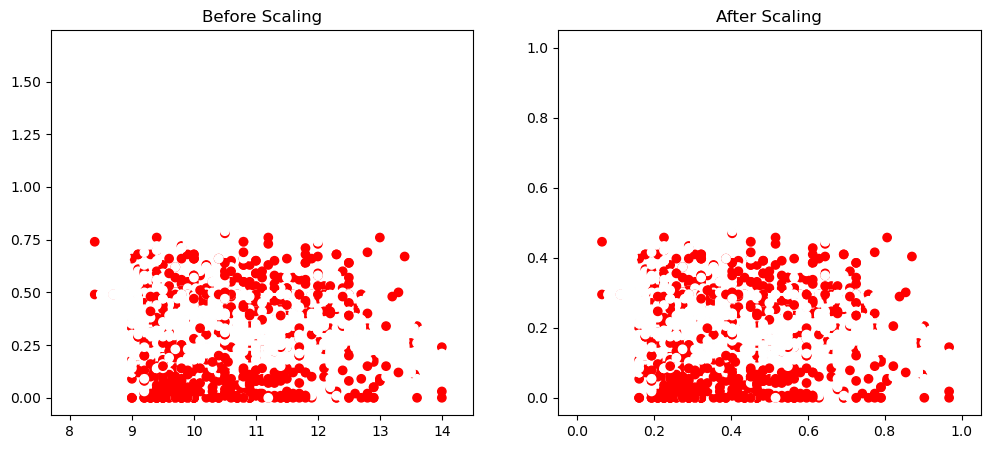

In [59]:
fig, (ax1,ax2) = plt.subplots(ncols=2,figsize=(12,5))

ax1.scatter(X_train['alcohol'],X_train['citric acid'], c=y_train)
ax1.set_title("Before Scaling")
ax2.scatter(X_train_scaled['alcohol'],X_train_scaled['citric acid'], c=y_train)
ax2.set_title("After Scaling")
plt.show()

#Ordinal Encoding

In [2]:
import pandas as pd
import numpy as np

In [3]:
rt = pd.read_csv('customer.csv')

In [23]:
rt.head()

,review,education,purchased
0,Average,School,No
1,Poor,UG,No
2,Good,PG,No
3,Good,PG,No
4,Average,UG,No


In [7]:
rt = rt.iloc[:,2:]

In [24]:
rt.head(40)

,review,education,purchased
0,Average,School,No
1,Poor,UG,No
2,Good,PG,No
3,Good,PG,No
4,Average,UG,No
5,Average,School,Yes
6,Good,School,No
7,Poor,School,Yes
8,Average,UG,No
9,Good,UG,Yes


In [9]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(rt.iloc[:,0:2],rt.iloc[:,-1],test_size=0.2)

In [10]:
X_train

,review,education
36,Good,UG
39,Poor,PG
24,Average,PG
41,Good,PG
32,Average,UG
6,Good,School
10,Good,UG
21,Average,PG
26,Poor,PG
9,Good,UG


In [11]:
from sklearn.preprocessing import OrdinalEncoder

In [12]:
oe = OrdinalEncoder(categories=[['Poor','Average','Good'],['School','UG','PG']])

In [13]:
oe.fit(X_train)

,categories,"[['Poor', 'Average', ...], ['School', 'UG', ...]]"
,dtype,<class 'numpy.float64'>
,handle_unknown,'error'
,unknown_value,None
,encoded_missing_value,nan
,min_frequency,None
,max_categories,None


In [14]:
X_train = oe.transform(X_train)
X_test = oe.transform(X_test)

In [15]:
X_train

array([[2., 1.],
       [0., 2.],
       [1., 2.],
       [2., 2.],
       [1., 1.],
       [2., 0.],
       [2., 1.],
       [1., 2.],
       [0., 2.],
       [2., 1.],
       [2., 2.],
       [0., 2.],
       [2., 1.],
       [0., 0.],
       [1., 0.],
       [0., 0.],
       [0., 0.],
       [2., 0.],
       [2., 2.],
       [0., 2.],
       [0., 2.],
       [1., 1.],
       [2., 1.],
       [2., 0.],
       [1., 1.],
       [0., 2.],
       [0., 0.],
       [1., 0.],
       [1., 2.],
       [1., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [2., 0.],
       [0., 2.],
       [2., 2.],
       [0., 2.],
       [2., 0.],
       [2., 0.],
       [0., 2.]])

In [16]:
oe.categories_

[array(['Poor', 'Average', 'Good'], dtype=object),
 array(['School', 'UG', 'PG'], dtype=object)]

#Label Encoding (for o/p)

In [17]:
from sklearn.preprocessing import LabelEncoder

In [18]:
le = LabelEncoder()

In [19]:
le.fit(y_train)

LabelEncoder()

In [20]:
le.classes_

array(['No', 'Yes'], dtype=object)

In [21]:
y_train = le.transform(y_train)
y_test = le.transform(y_test)

In [25]:
y_train

array([1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1,
       0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0])

#One Hot Encoding

In [53]:
import numpy as np
import pandas as pd

In [54]:
df = pd.read_csv('cars.csv')

In [55]:
df.head()

,brand,km_driven,fuel,owner,selling_price
0,Maruti,145500,Diesel,First Owner,450000
1,Skoda,120000,Diesel,Second Owner,370000
2,Honda,140000,Petrol,Third Owner,158000
3,Hyundai,127000,Diesel,First Owner,225000
4,Maruti,120000,Petrol,First Owner,130000


In [56]:
df['brand'].value_counts()

brand
Maruti           2448
Hyundai          1415
Mahindra          772
Tata              734
Toyota            488
Honda             467
Ford              397
Chevrolet         230
Renault           228
Volkswagen        186
BMW               120
Skoda             105
Nissan             81
Jaguar             71
Volvo              67
Datsun             65
Mercedes-Benz      54
Fiat               47
Audi               40
Lexus              34
Jeep               31
Mitsubishi         14
Force               6
Land                6
Isuzu               5
Kia                 4
Ambassador          4
Daewoo              3
MG                  3
Ashok               1
Opel                1
Peugeot             1
Name: count, dtype: int64

##One Hot Endoing using Pandas

In [57]:
pd.get_dummies(df,columns=['fuel','owner'])

,brand,km_driven,selling_price,fuel_CNG,fuel_Diesel,fuel_LPG,fuel_Petrol,owner_First Owner,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,Maruti,145500,450000,False,True,False,False,True,False,False,False,False
1,Skoda,120000,370000,False,True,False,False,False,False,True,False,False
2,Honda,140000,158000,False,False,False,True,False,False,False,False,True
3,Hyundai,127000,225000,False,True,False,False,True,False,False,False,False
4,Maruti,120000,130000,False,False,False,True,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
8123,Hyundai,110000,320000,False,False,False,True,True,False,False,False,False
8124,Hyundai,119000,135000,False,True,False,False,False,True,False,False,False
8125,Maruti,120000,382000,False,True,False,False,True,False,False,False,False
8126,Tata,25000,290000,False,True,False,False,True,False,False,False,False


N-1 Encoding

In [58]:
pd.get_dummies(df,columns=['fuel','owner'],drop_first=True)

,brand,km_driven,selling_price,fuel_Diesel,fuel_LPG,fuel_Petrol,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,Maruti,145500,450000,True,False,False,False,False,False,False
1,Skoda,120000,370000,True,False,False,False,True,False,False
2,Honda,140000,158000,False,False,True,False,False,False,True
3,Hyundai,127000,225000,True,False,False,False,False,False,False
4,Maruti,120000,130000,False,False,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...
8123,Hyundai,110000,320000,False,False,True,False,False,False,False
8124,Hyundai,119000,135000,True,False,False,True,False,False,False
8125,Maruti,120000,382000,True,False,False,False,False,False,False
8126,Tata,25000,290000,True,False,False,False,False,False,False


Using SkLearn One Hot Encoding

In [59]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df.iloc[:,0:4],df.iloc[:,-1],test_size=0.2)

In [60]:
X_train.head()

,brand,km_driven,fuel,owner
4045,Hyundai,120000,LPG,First Owner
7681,Maruti,120000,Diesel,First Owner
2914,Ford,54000,Diesel,First Owner
6830,Ford,112000,Diesel,Second Owner
3158,Ford,70000,Diesel,Second Owner


In [61]:
from sklearn.preprocessing import OneHotEncoder

In [62]:
ohe = OneHotEncoder(dtype=np.int32,drop='first')

In [63]:
X_train_new = ohe.fit_transform(X_train[['fuel','owner']]).toarray()

In [64]:
X_test_new = ohe.fit_transform(X_test[['fuel','owner']]).toarray()

In [65]:
X_train_new

array([[0, 1, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0],
       ...,
       [1, 0, 0, ..., 0, 0, 0],
       [0, 0, 1, ..., 0, 0, 0],
       [1, 0, 0, ..., 1, 0, 0]], shape=(6502, 7), dtype=int32)

In [68]:
np.hstack((X_train[['brand','km_driven']].values,X_train_new))

array([['Hyundai', 50000, 0, ..., 0, 0, 0],
       ['Renault', 25000, 0, ..., 0, 0, 0],
       ['Jeep', 17000, 0, ..., 0, 0, 0],
       ...,
       ['Tata', 15000, 0, ..., 0, 0, 0],
       ['Tata', 90000, 1, ..., 1, 0, 0],
       ['Volkswagen', 120000, 1, ..., 0, 0, 1]],
      shape=(6502, 9), dtype=object)

One Hot Encoding with Top Categories

In [71]:
counts = df['brand'].value_counts()

In [73]:
df['brand'].unique()
threshold = 100

In [74]:
repl = counts[counts<=threshold].index

In [75]:
pd.get_dummies(df['brand'].replace(repl,'uncommon'))

,BMW,Chevrolet,Ford,Honda,Hyundai,Mahindra,Maruti,Renault,Skoda,Tata,Toyota,Volkswagen,uncommon
0,False,False,False,False,False,False,True,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,True,False,False,False,False
2,False,False,False,True,False,False,False,False,False,False,False,False,False
3,False,False,False,False,True,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,True,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8123,False,False,False,False,True,False,False,False,False,False,False,False,False
8124,False,False,False,False,True,False,False,False,False,False,False,False,False
8125,False,False,False,False,False,False,True,False,False,False,False,False,False
8126,False,False,False,False,False,False,False,False,False,True,False,False,False


Column Transformation

In [1]:
import pandas as pd
import numpy as np

In [2]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer

In [3]:
df = pd.read_csv('covid_toy.csv')

In [4]:
df.head()

,age,gender,fever,cough,city,has_covid
0,60,Male,103.0,Mild,Kolkata,No
1,27,Male,100.0,Mild,Delhi,Yes
2,42,Male,101.0,Mild,Delhi,No
3,31,Female,98.0,Mild,Kolkata,No
4,65,Female,101.0,Mild,Mumbai,No


In [6]:
df['cough'].value_counts()

cough
Mild      62
Strong    38
Name: count, dtype: int64

In [7]:
df.isnull().sum()

age           0
gender        0
fever        10
cough         0
city          0
has_covid     0
dtype: int64

In [9]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df.drop(columns=['has_covid']),df['has_covid'],test_size=0.2)

In [11]:
X_train.head()

,age,gender,fever,cough,city
44,20,Male,102.0,Strong,Delhi
90,59,Female,99.0,Strong,Delhi
31,83,Male,103.0,Mild,Kolkata
15,70,Male,103.0,Strong,Kolkata
22,71,Female,98.0,Strong,Kolkata


Without Column tranformation

In [12]:
#adding simple to fever
si = SimpleImputer()
X_train_fever = si.fit_transform(X_train[['fever']])
X_test_fever = si.fit_transform(X_test[['fever']])

X_train.fever

44    102.0
90     99.0
31    103.0
15    103.0
22     98.0
      ...  
25      NaN
37    100.0
99     98.0
83    104.0
50    101.0
Name: fever, Length: 80, dtype: float64

In [13]:
#Ordinal on cough
oe = OrdinalEncoder(categories=[['Mild','Strong']])
X_train_cough = oe.fit_transform(X_train[['cough']])
X_test_cough = oe.fit_transform(X_test[['cough']])
X_train_cough.shape

(80, 1)

In [37]:
#OneHot on gender,city
ohe = OneHotEncoder(drop='first',sparse_output=False)
X_train_gender = ohe.fit_transform(X_train[['gender','city']])
X_test_gender = ohe.fit_transform(X_test[['gender','city']])
X_train_gender.shape

(80, 4)

In [38]:
#extracting age
X_train_age = X_train.drop(columns=['gender','fever','cough','city']).values
X_test_age = X_test.drop(columns=['gender','fever','cough','city']).values


In [46]:
X_train_trans = np.concatenate((X_train_age,X_train_fever,X_train_gender,X_train_cough),axis=1)
X_test_trans = np.concatenate((X_test_age,X_test_fever,X_test_gender,X_test_cough),axis=1)
X_train_trans.shape

(80, 7)

#Column Transformer

In [40]:
from sklearn.compose import ColumnTransformer

In [44]:
transf = ColumnTransformer(transformers=[
    ('tnf1',SimpleImputer(),['fever']),
    ('tnf2',OrdinalEncoder(categories=[['Mild','Strong']]),['cough']),
    ('tnf3',OneHotEncoder(sparse_output=False,drop='first'),['gender','city'])
],remainder='passthrough')

In [47]:
transf.fit_transform(X_train).shape

(80, 7)